# Обработка изображения SAR — задание 1

В работе использовано изображение sar_1_gray.jpg. Все результаты вывожу прямо в ноутбуке.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.metrics import mean_squared_error, structural_similarity

plt.rcParams['figure.dpi'] = 100

## 1. Загрузка изображения в оттенках серого

Сначала загружаю файл с флагом IMREAD_GRAYSCALE, чтобы получить одноканальное изображение.

Путь к файлу: D:\DownLoads\sar_1_gray.jpg
Размер изображения: (400, 600)
Тип данных: uint8


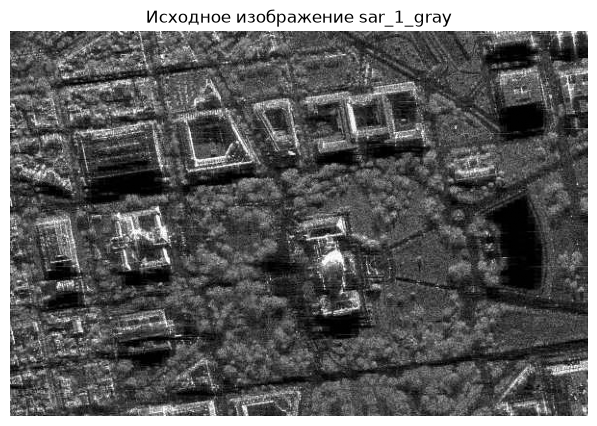

In [2]:
possible_paths = [
    Path('sar_1_gray.jpg'),
    Path(r'D:\DownLoads\sar_1_gray.jpg')
]

image_path = next((p for p in possible_paths if p.exists()), None)
if image_path is None:
    raise FileNotFoundError('Файл sar_1_gray.jpg не найден')

gray_image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
print('Путь к файлу:', image_path)
print('Размер изображения:', gray_image.shape)
print('Тип данных:', gray_image.dtype)

plt.figure(figsize=(8, 5))
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение sar_1_gray')
plt.axis('off')
plt.show()

## 2. Гистограмма изображения

Гистограмма показывает, сколько пикселей имеет каждую яркость от 0 до 255.

Средняя яркость: 74.94
Стандартное отклонение: 43.66


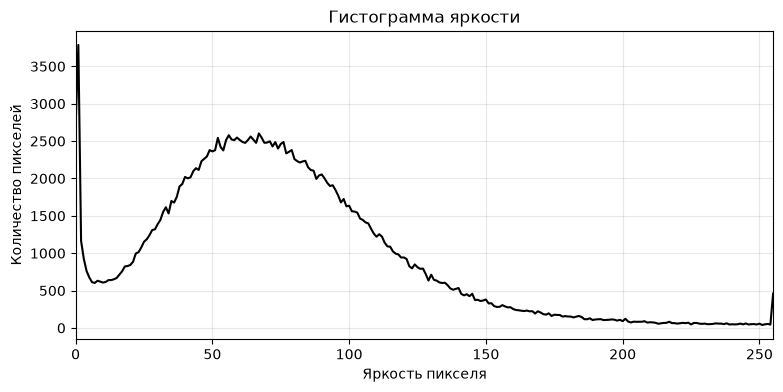

In [3]:
hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])

plt.figure(figsize=(9, 4))
plt.plot(hist, color='black')
plt.title('Гистограмма яркости')
plt.xlabel('Яркость пикселя')
plt.ylabel('Количество пикселей')
plt.xlim(0, 255)
plt.grid(alpha=0.3)
plt.show()

print('Средняя яркость:', round(gray_image.mean(), 2))
print('Стандартное отклонение:', round(gray_image.std(), 2))

## 3. Гамма-коррекция

Использую формулу new = 255 * (old / 255) ** gamma. При gamma меньше 1 изображение становится светлее, а при gamma больше 1 — темнее.

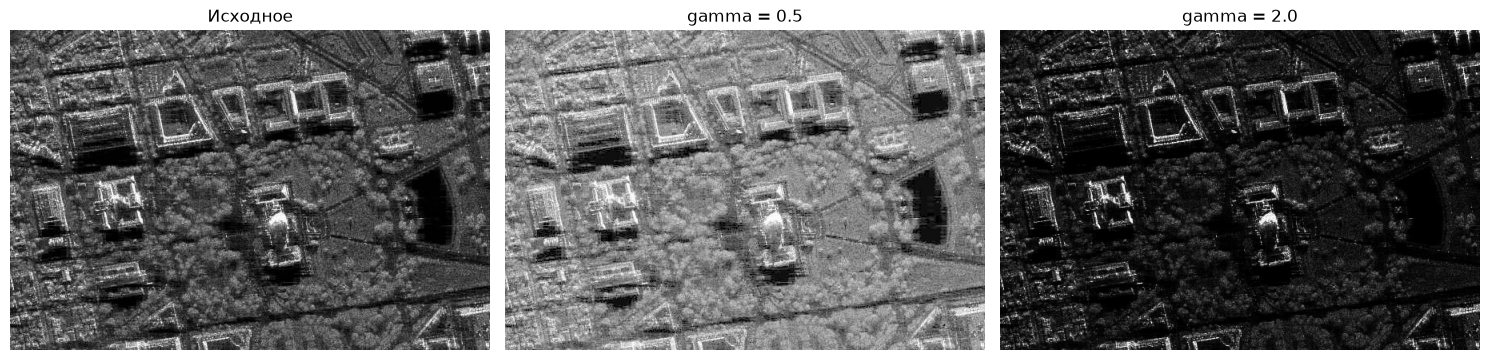

In [4]:
def gamma_correction(image, gamma):
    table = np.zeros(256, dtype=np.uint8)
    for i in range(256):
        table[i] = np.clip(255 * (i / 255) ** gamma, 0, 255)
    return cv2.LUT(image, table)


gamma_light = gamma_correction(gray_image, 0.5)
gamma_dark = gamma_correction(gray_image, 2.0)

images = [gray_image, gamma_light, gamma_dark]
names = ['Исходное', 'gamma = 0.5', 'gamma = 2.0']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, name in zip(axes, images, names):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Сравнение результатов гамма-коррекции

Для сравнения использую MSE (среднеквадратичная ошибка) и SSIM (похожесть структуры). Чем MSE меньше и SSIM ближе к 1, тем изображения похожее.

gamma = 0.5: MSE = 3250.43, SSIM = 0.7875
gamma = 2.0: MSE = 2383.76, SSIM = 0.5270


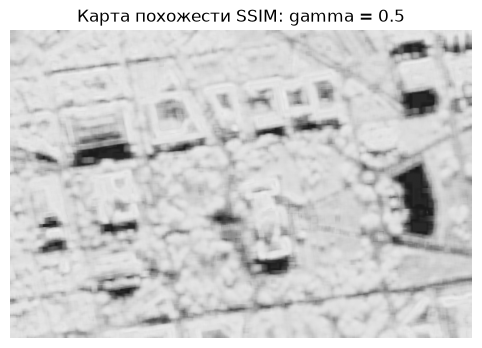

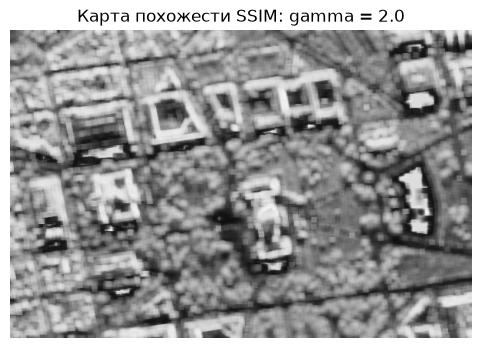

In [5]:
for name, image in [('gamma = 0.5', gamma_light), ('gamma = 2.0', gamma_dark)]:
    mse = mean_squared_error(gray_image, image)
    ssim, diff = structural_similarity(gray_image, image, full=True)
    print(f'{name}: MSE = {mse:.2f}, SSIM = {ssim:.4f}')

    plt.figure(figsize=(7, 4))
    plt.imshow(diff, cmap='gray', vmin=0, vmax=1)
    plt.title(f'Карта похожести SSIM: {name}')
    plt.axis('off')
    plt.show()

**Вывод.** При gamma = 0.5 лучше видны тёмные участки, а при gamma = 2.0 изображение заметно темнеет. В обоих случаях SSIM меньше 1, потому что яркости пикселей изменились.

## 5. Статистическая коррекция по статистике eq_gray

Сначала делаю эквализацию гистограммы и использую её как образец. Затем у исходного изображения меняю среднее и стандартное отклонение так, чтобы они приблизились к статистике образца.

Исходное:     mean = 74.94 , std = 43.66
eq_gray:      mean = 127.03 , std = 74.27
Коррекция:    mean = 123.12 , std = 65.3


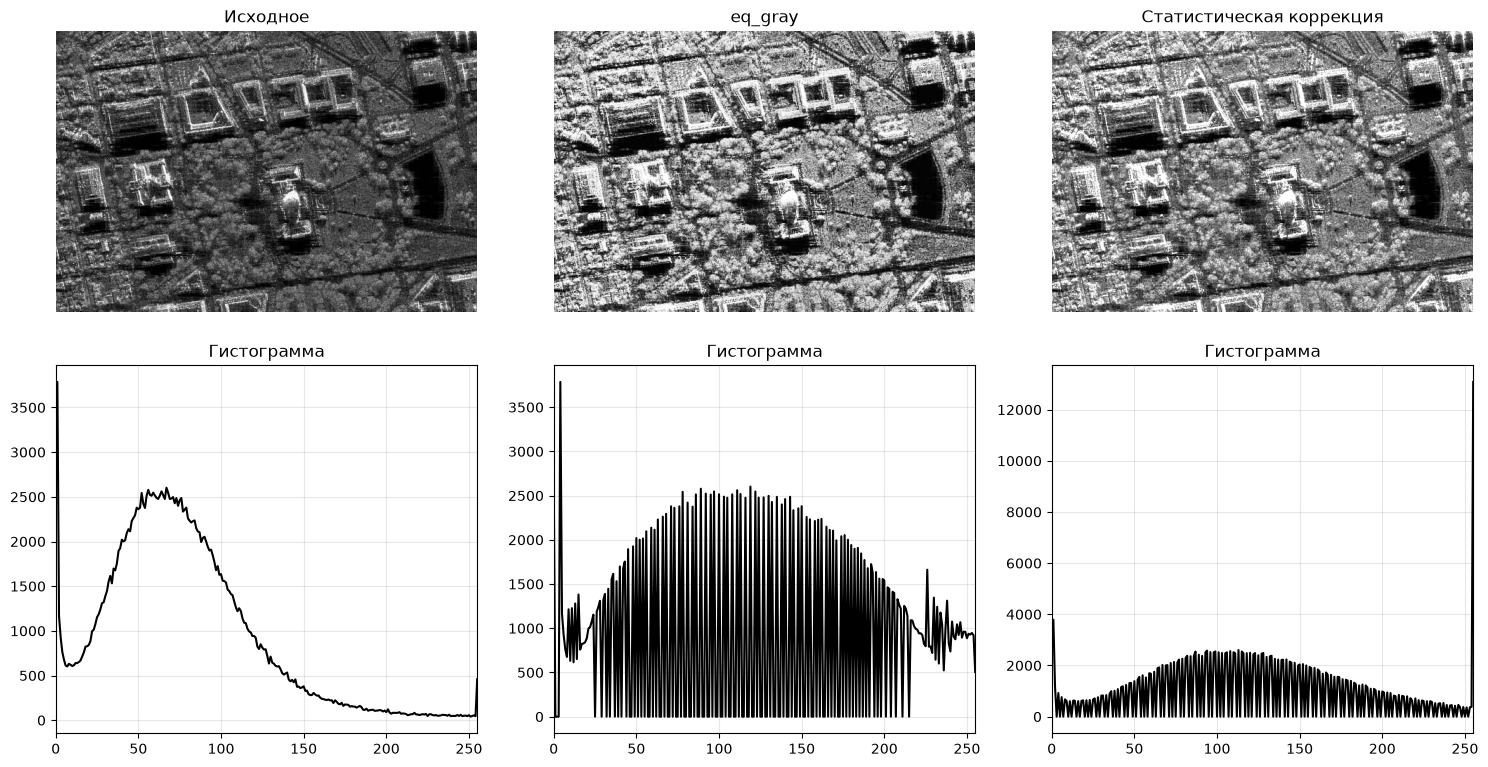

In [6]:
eq_gray = cv2.equalizeHist(gray_image)

mean_source = gray_image.mean()
std_source = gray_image.std()
mean_sample = eq_gray.mean()
std_sample = eq_gray.std()

corrected = mean_sample + (gray_image.astype(np.float32) - mean_source) * std_sample / std_source
corrected = np.clip(corrected, 0, 255).astype(np.uint8)

print('Исходное:     mean =', round(mean_source, 2), ', std =', round(std_source, 2))
print('eq_gray:      mean =', round(mean_sample, 2), ', std =', round(std_sample, 2))
print('Коррекция:    mean =', round(corrected.mean(), 2), ', std =', round(corrected.std(), 2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (image, name) in enumerate(zip([gray_image, eq_gray, corrected],
                                      ['Исходное', 'eq_gray', 'Статистическая коррекция'])):
    axes[0, i].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(name)
    axes[0, i].axis('off')

    h = cv2.calcHist([image], [0], None, [256], [0, 256])
    axes[1, i].plot(h, color='black')
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_title('Гистограмма')
    axes[1, i].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод.** После статистической коррекции среднее значение и разброс яркостей близки к eq_gray. При этом изображение выглядит контрастнее, чем исходное.

## 6. Пороговая фильтрация с разными параметрами

Сравню несколько значений порога для бинарной фильтрации и несколько режимов пороговой обработки.

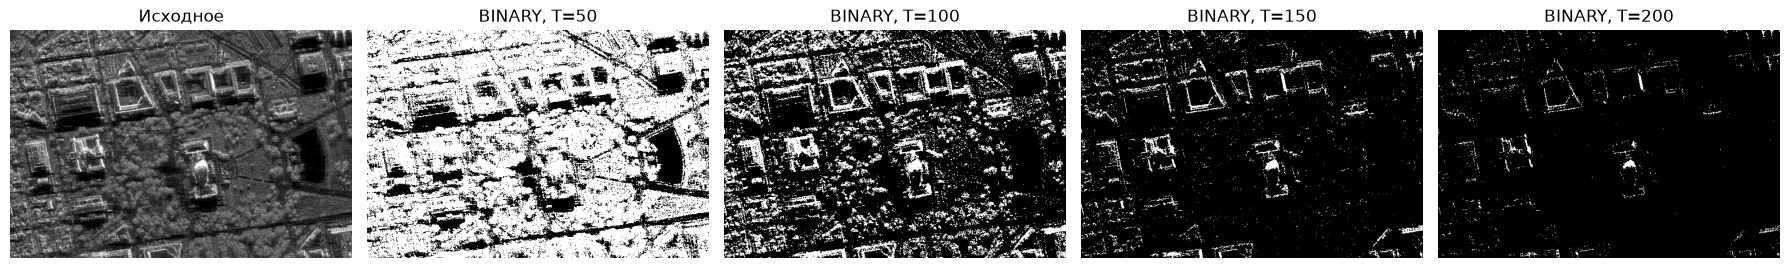

In [7]:
thresholds = [50, 100, 150, 200]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(gray_image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Исходное')
axes[0].axis('off')

for ax, threshold in zip(axes[1:], thresholds):
    _, binary = cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)
    ax.imshow(binary, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'BINARY, T={threshold}')
    ax.axis('off')
plt.tight_layout()
plt.show()

Порог, найденный методом Оцу: 85.0


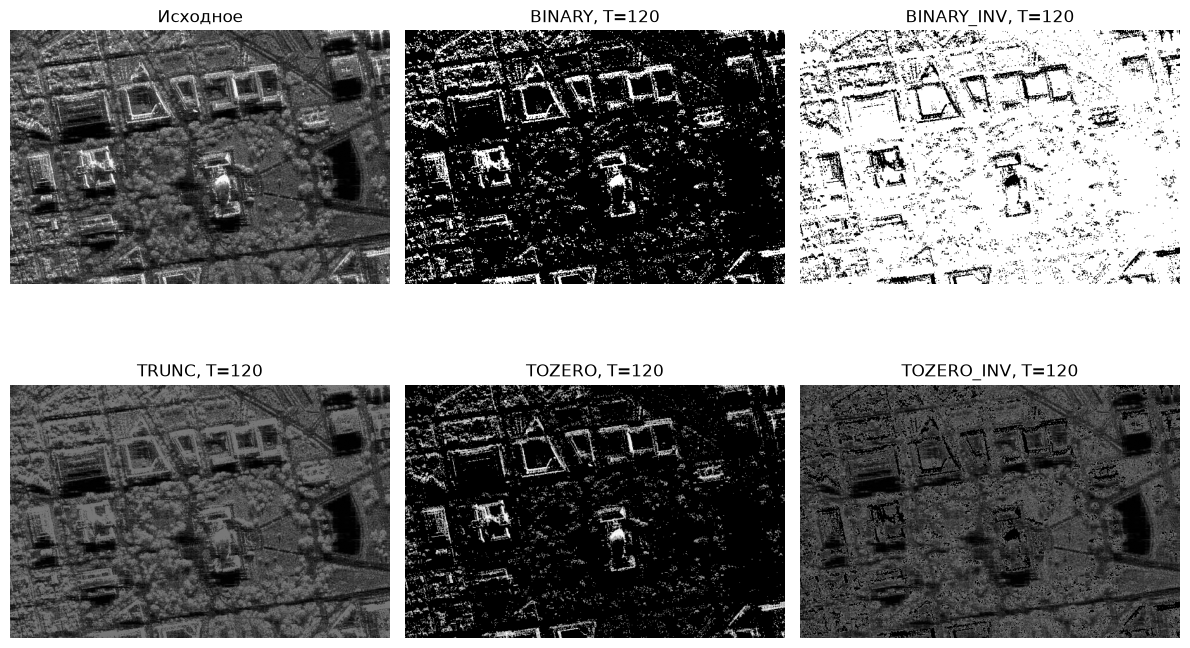

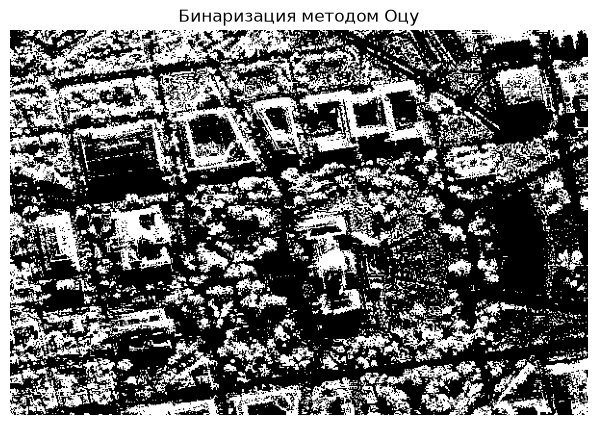

In [8]:
modes = [
    ('BINARY', cv2.THRESH_BINARY),
    ('BINARY_INV', cv2.THRESH_BINARY_INV),
    ('TRUNC', cv2.THRESH_TRUNC),
    ('TOZERO', cv2.THRESH_TOZERO),
    ('TOZERO_INV', cv2.THRESH_TOZERO_INV)
]

threshold = 120
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

axes[0].imshow(gray_image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Исходное')

for ax, (name, mode) in zip(axes[1:], modes):
    _, result = cv2.threshold(gray_image, threshold, 255, mode)
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{name}, T={threshold}')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

otsu_threshold, otsu_image = cv2.threshold(gray_image, 0, 255,
                                             cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('Порог, найденный методом Оцу:', round(otsu_threshold, 1))
plt.figure(figsize=(8, 5))
plt.imshow(otsu_image, cmap='gray', vmin=0, vmax=255)
plt.title('Бинаризация методом Оцу')
plt.axis('off')
plt.show()

**Общий вывод.** Гамма-коррекция позволяет осветлять или затемнять SAR-снимок. Статистическая коррекция меняет контраст по статистике образца, а пороговая фильтрация выделяет участки с яркостью выше или ниже выбранного значения.